In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time

from bs4 import BeautifulSoup
from urllib.parse import urljoin

print("Data Science 500 - Book Market Analytics")
print("Libraries imported successfully!")

Data Science 500 - Book Market Analytics
Libraries imported successfully!


In [2]:
BASE_URL = "https://books.toscrape.com/"
HEADERS = {"User-Agent": "Mozilla/5.0"}

books = []
page_url = BASE_URL

while page_url:
    response = requests.get(
        page_url, headers=HEADERS, timeout=30
    )
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    products = soup.select("article.product_pod")
    for product in products:
        title = product.h3.a["title"]

        price_text = product.select_one(
            ".price_color"
        ).get_text(strip=True)

        price = float(
            re.sub(r"[^0-9.]", "", price_text)
        )

        rating_word = product.select_one(
            ".star-rating"
        )["class"][-1]

        rating_map = {
            "One": 1,
            "Two": 2,
            "Three": 3,
            "Four": 4,
            "Five": 5
        }

        rating = rating_map[rating_word]
        book_url = urljoin(
            page_url, product.h3.a["href"]
        )

        detail_response = requests.get(
            book_url, headers=HEADERS, timeout=30
        )
        detail_response.raise_for_status()

        detail = BeautifulSoup(
            detail_response.text, "html.parser"
        )
        availability = detail.select_one(
            ".availability"
        )

        stock_text = (
            availability.get_text(" ", strip=True)
            if availability else "Unknown"
        )

        match = re.search(
            r"\((\d+)\s+available\)", stock_text
        )

        quantity = (
            int(match.group(1)) if match else None
        )

        stock_status = (
            "In stock"
            if "in stock" in stock_text.lower()
            else "Out of stock"
            if "out of stock" in stock_text.lower()
            else "Unknown"
        )
        breadcrumb = detail.select(
            "ul.breadcrumb li a"
        )

        genre = (
            breadcrumb[-1].get_text(strip=True)
            if len(breadcrumb) >= 3
            else "Unknown"
        )
        description_element = detail.select_one(
            "#product_description + p"
        )

        description = (
            description_element.get_text(strip=True)
            if description_element else ""
        )

        books.append({
            "title": title,
            "price_gbp": price,
            "rating_word": rating_word,
            "rating": rating,
            "stock_status": stock_status,
            "stock_quantity": quantity,
            "genre": genre,
            "description": description,
            "product_url": book_url
        })

        time.sleep(0.1)
    next_link = soup.select_one("li.next a")

    if next_link:
        page_url = urljoin(
            page_url, next_link["href"]
        )
    else:
        page_url = None

    print("Books collected:", len(books))

print("Data acquisition completed!")
print("Total books collected:", len(books))

Books collected: 20
Books collected: 40
Books collected: 60
Books collected: 80
Books collected: 100
Books collected: 120
Books collected: 140
Books collected: 160
Books collected: 180
Books collected: 200
Books collected: 220
Books collected: 240
Books collected: 260
Books collected: 280
Books collected: 300
Books collected: 320
Books collected: 340
Books collected: 360
Books collected: 380
Books collected: 400
Books collected: 420
Books collected: 440
Books collected: 460
Books collected: 480
Books collected: 500
Books collected: 520
Books collected: 540
Books collected: 560
Books collected: 580
Books collected: 600
Books collected: 620
Books collected: 640
Books collected: 660
Books collected: 680
Books collected: 700
Books collected: 720
Books collected: 740
Books collected: 760
Books collected: 780
Books collected: 800
Books collected: 820
Books collected: 840
Books collected: 860
Books collected: 880
Books collected: 900
Books collected: 920
Books collected: 940
Books collected: 

In [3]:
df = pd.DataFrame(books)

df.to_csv("books_dataset.csv", index=False)

print("Dataset saved successfully!")
print("Total books:", len(df))
print("Number of columns:", len(df.columns))

display(df.head(10))

Dataset saved successfully!
Total books: 1000
Number of columns: 9


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,genre,description,product_url
0,A Light in the Attic,51.77,Three,3,In stock,22,Poetry,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In stock,20,Historical Fiction,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In stock,20,Fiction,"Dans une France assez proche de la nÃ´tre, un ...",https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In stock,20,Mystery,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,20,History,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,22.65,One,1,In stock,19,Young Adult,Patient Twenty-nine.A monster roams the halls ...,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,33.34,Four,4,In stock,19,Business,Drawing on his extensive experience evaluating...,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,17.93,Three,3,In stock,19,Default,"""If you have a heart, if you have a soul, Kare...",https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,22.60,Four,4,In stock,19,Default,For readers of Laura Hillenbrand's Seabiscuit ...,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,52.15,One,1,In stock,19,Poetry,"Praise for Aracelis Girmay:""[Girmay's] every l...",https://books.toscrape.com/catalogue/the-black...


In [4]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate book titles:")
print(df["title"].duplicated().sum())

print("\nNumber of unique genres:")
print(df["genre"].nunique())

print("\nSummary of numerical data:")
display(df[["price_gbp", "rating", "stock_quantity"]].describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   title           1000 non-null   str    
 1   price_gbp       1000 non-null   float64
 2   rating_word     1000 non-null   str    
 3   rating          1000 non-null   int64  
 4   stock_status    1000 non-null   str    
 5   stock_quantity  1000 non-null   int64  
 6   genre           1000 non-null   str    
 7   description     1000 non-null   str    
 8   product_url     1000 non-null   str    
dtypes: float64(1), int64(2), str(6)
memory usage: 70.4 KB

Missing values in each column:
title             0
price_gbp         0
rating_word       0
rating            0
stock_status      0
stock_quantity    0
genre             0
description       0
product_url       0
dtype: int64

Duplicate book titles:
1

Number of unique genres:
50

Summary of numerical data:


,price_gbp,rating,stock_quantity
count,1000.00000,1000.000000,1000.000000
mean,35.07035,2.923000,8.585000
std,14.44669,1.434967,5.654622
min,10.00000,1.000000,1.000000
25%,22.10750,2.000000,3.000000
50%,35.98000,3.000000,7.000000
75%,47.45750,4.000000,14.000000
max,59.99000,5.000000,22.000000


In [5]:
import pandas as pd
df = pd.DataFrame(books)
df.to_csv("books_dataset.csv", index=False)

print("Dataset saved successfully!")
print("Total books:", len(df))

display(df.head())

Dataset saved successfully!
Total books: 1000


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,genre,description,product_url
0,A Light in the Attic,51.77,Three,3,In stock,22,Poetry,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In stock,20,Historical Fiction,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In stock,20,Fiction,"Dans une France assez proche de la nÃ´tre, un ...",https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In stock,20,Mystery,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,20,History,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...


In [6]:
print("Dataset shape (rows, columns):")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate book titles:")
print(df["title"].duplicated().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nSummary of numerical columns:")
display(
    df[["price_gbp", "rating", "stock_quantity"]].describe()
)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape (rows, columns):
(1000, 9)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   title           1000 non-null   str    
 1   price_gbp       1000 non-null   float64
 2   rating_word     1000 non-null   str    
 3   rating          1000 non-null   int64  
 4   stock_status    1000 non-null   str    
 5   stock_quantity  1000 non-null   int64  
 6   genre           1000 non-null   str    
 7   description     1000 non-null   str    
 8   product_url     1000 non-null   str    
dtypes: float64(1), int64(2), str(6)
memory usage: 70.4 KB

Missing values in each column:
title             0
price_gbp         0
rating_word       0
rating            0
stock_status      0
stock_quantity    0
genre             0
description       0
product_url       0
dtype: int64

Number of duplicate book titles:
1

Number of duplicate rows:
0

,price_gbp,rating,stock_quantity
count,1000.00000,1000.000000,1000.000000
mean,35.07035,2.923000,8.585000
std,14.44669,1.434967,5.654622
min,10.00000,1.000000,1.000000
25%,22.10750,2.000000,3.000000
50%,35.98000,3.000000,7.000000
75%,47.45750,4.000000,14.000000
max,59.99000,5.000000,22.000000



First 5 rows:


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,genre,description,product_url
0,A Light in the Attic,51.77,Three,3,In stock,22,Poetry,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In stock,20,Historical Fiction,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In stock,20,Fiction,"Dans une France assez proche de la nÃ´tre, un ...",https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In stock,20,Mystery,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,20,History,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...


In [7]:
df_clean = df.copy()

# I added this to remove duplicate rows and duplicate book titles
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.drop_duplicates(subset="title")
df_clean["price_gbp"] = pd.to_numeric(
    df_clean["price_gbp"], errors="coerce"
)

df_clean["rating"] = pd.to_numeric(
    df_clean["rating"], errors="coerce"
)

df_clean["stock_quantity"] = pd.to_numeric(
    df_clean["stock_quantity"], errors="coerce"
)

df_clean = df_clean.dropna(
    subset=["price_gbp", "rating"]
)

df_clean["genre"] = df_clean["genre"].fillna("Unknown")
df_clean["description"] = df_clean["description"].fillna("")
df_clean["stock_status"] = df_clean["stock_status"].fillna("Unknown")

df_clean.to_csv("books_dataset_cleaned.csv", index=False)

print("Data cleaning completed!")
print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

display(df_clean.head())

Data cleaning completed!
Rows before cleaning: 1000
Rows after cleaning: 999
Missing values after cleaning:
title             0
price_gbp         0
rating_word       0
rating            0
stock_status      0
stock_quantity    0
genre             0
description       0
product_url       0
dtype: int64


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,genre,description,product_url
0,A Light in the Attic,51.77,Three,3,In stock,22,Poetry,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In stock,20,Historical Fiction,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In stock,20,Fiction,"Dans une France assez proche de la nÃ´tre, un ...",https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In stock,20,Mystery,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,20,History,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Visualisation libraries are ready!")

Visualisation libraries are ready!


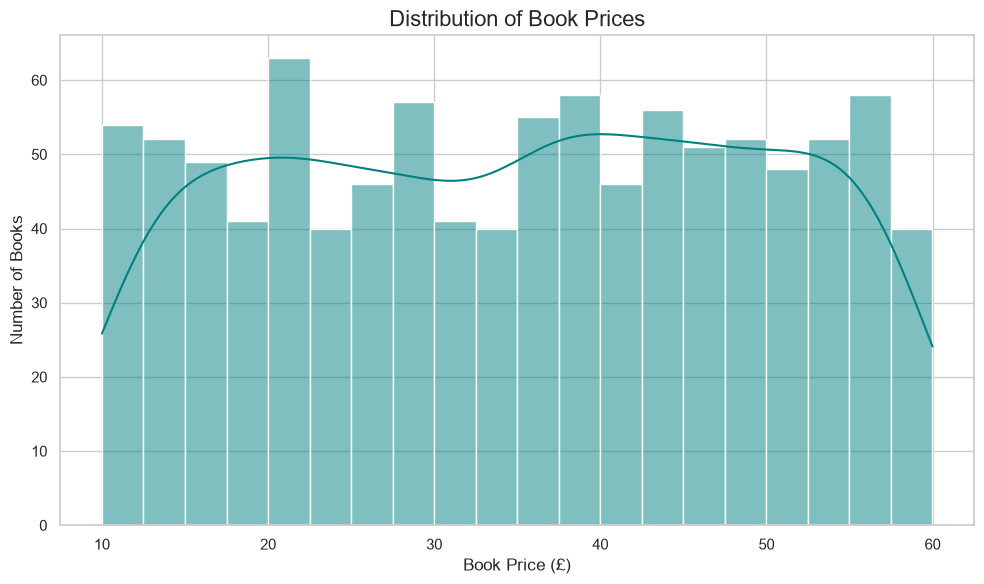

In [19]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="price_gbp",
    bins=20,
    kde=True,
    color="teal"
)

plt.title("Distribution of Book Prices", fontsize=16)
plt.xlabel("Book Price (£)", fontsize=12)
plt.ylabel("Number of Books", fontsize=12)

plt.tight_layout()
plt.show()

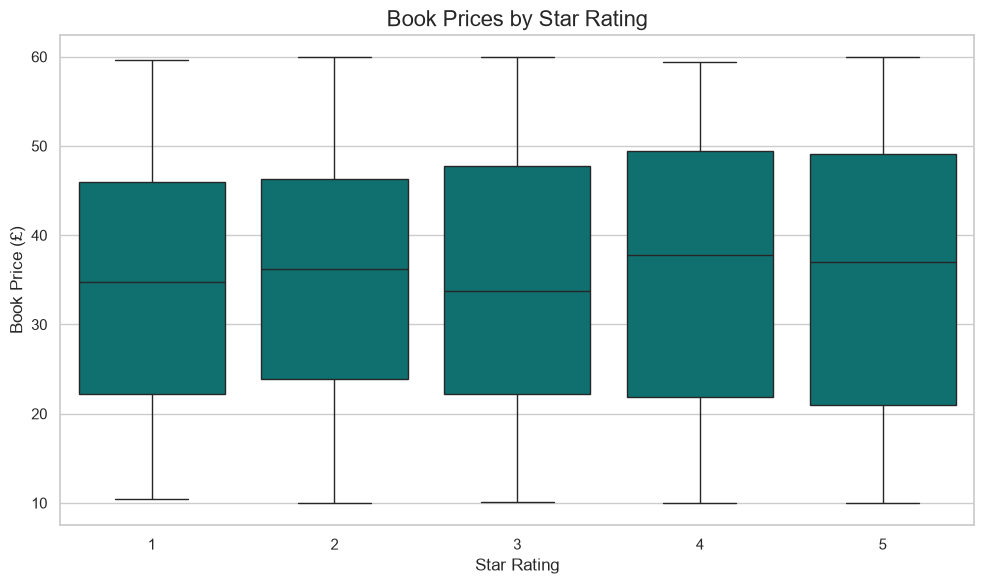

In [37]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="rating",
    y="price_gbp",
    color="teal"
)

plt.title("Book Prices by Star Rating", fontsize=16)
plt.xlabel("Star Rating", fontsize=12)
plt.ylabel("Book Price (£)", fontsize=12)

plt.tight_layout()
plt.show()

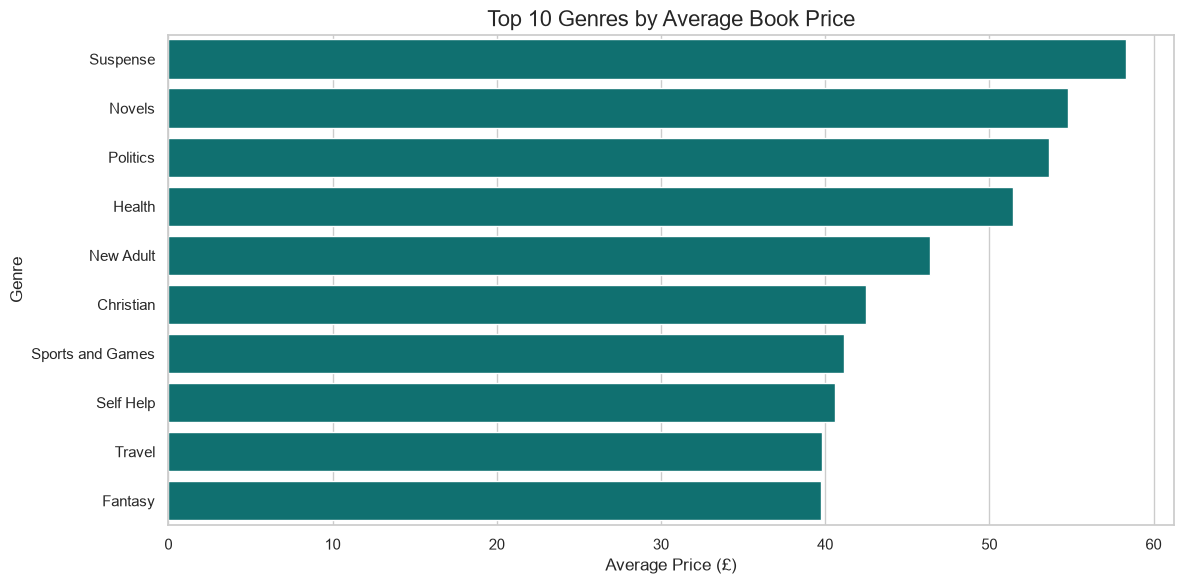

In [11]:
genre_prices = (
    df_clean.groupby("genre")["price_gbp"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_prices.values,
    y=genre_prices.index,
    color="teal"
)

plt.title("Top 10 Genres by Average Book Price", fontsize=16)
plt.xlabel("Average Price (£)", fontsize=12)
plt.ylabel("Genre", fontsize=12)

plt.tight_layout()
plt.show()

In [12]:
print("BOOK MARKET SUMMARY")
print("-" * 35)

print("Number of books:", len(df_clean))
print(f"Average price: £{df_clean['price_gbp'].mean():.2f}")
print(f"Median price: £{df_clean['price_gbp'].median():.2f}")
print(f"Minimum price: £{df_clean['price_gbp'].min():.2f}")
print(f"Maximum price: £{df_clean['price_gbp'].max():.2f}")
print(f"Average star rating: {df_clean['rating'].mean():.2f}")

print("\nNumber of books by rating:")
print(df_clean["rating"].value_counts().sort_index())

BOOK MARKET SUMMARY
-----------------------------------
Number of books: 999
Average price: £35.07
Median price: £36.00
Minimum price: £10.00
Maximum price: £59.99
Average star rating: 2.92

Number of books by rating:
rating
1    226
2    196
3    203
4    179
5    195
Name: count, dtype: int64


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [14]:
X = df_clean[["rating"]]
y = df_clean["price_gbp"]

print("Predictor variable: Rating")
print("Target variable: Book price")
print("Number of records:", len(df_clean))

Predictor variable: Rating
Target variable: Book price
Number of records: 999


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Model training completed!
Training records: 799
Testing records: 200


In [16]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print(f"Mean Absolute Error (MAE): £{mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R²): {r2:.4f}")
print(f"Model coefficient: {model.coef_[0]:.4f}")
print(f"Model intercept: {model.intercept_:.4f}")

Mean Absolute Error (MAE): £12.23
Mean Squared Error (MSE): 200.93
R-squared (R²): -0.0053
Model coefficient: 0.3843
Model intercept: 34.1136


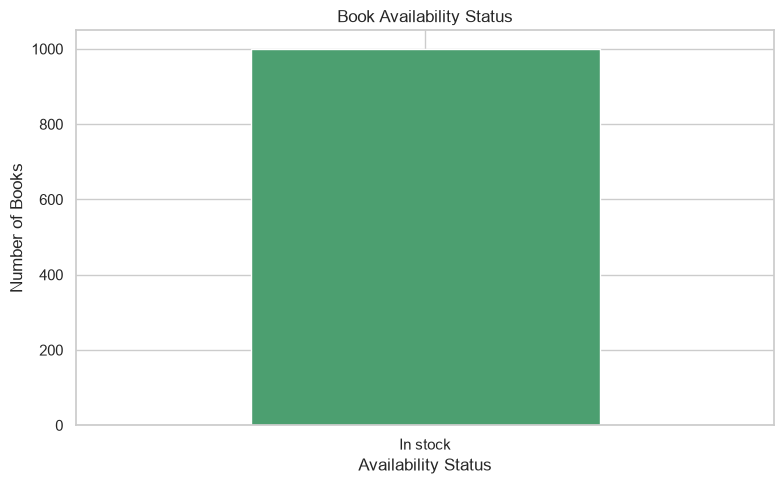

stock_status
In stock    999
Name: count, dtype: int64


In [20]:
availability_counts = df_clean["stock_status"].value_counts()

plt.figure(figsize=(8, 5))
availability_counts.plot(
    kind="bar",
    color=["#4C9F70", "#E07A5F", "#8D99AE"]
)

plt.title("Book Availability Status")
plt.xlabel("Availability Status")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(availability_counts)

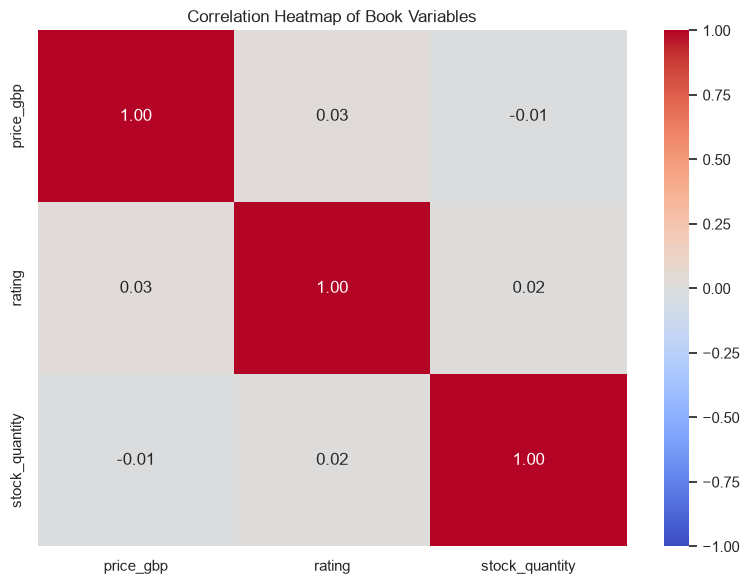

In [36]:
numeric_data = df_clean[
    ["price_gbp", "rating", "stock_quantity"]
].copy()

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Book Variables")
plt.tight_layout()
plt.show()

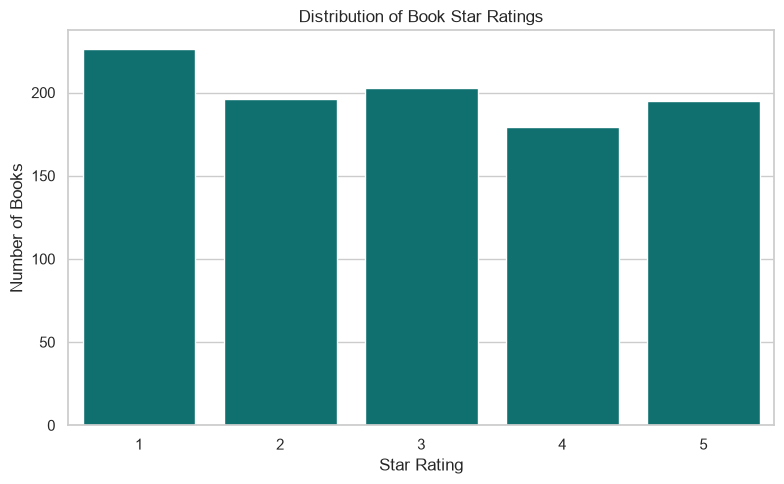

rating
1    226
2    196
3    203
4    179
5    195
Name: count, dtype: int64


In [31]:
rating_counts = (
    df_clean["rating"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    color="teal"
)

plt.title("Distribution of Book Star Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks([0, 1, 2, 3, 4], ["1", "2", "3", "4", "5"])
plt.tight_layout()
plt.show()

print(rating_counts)

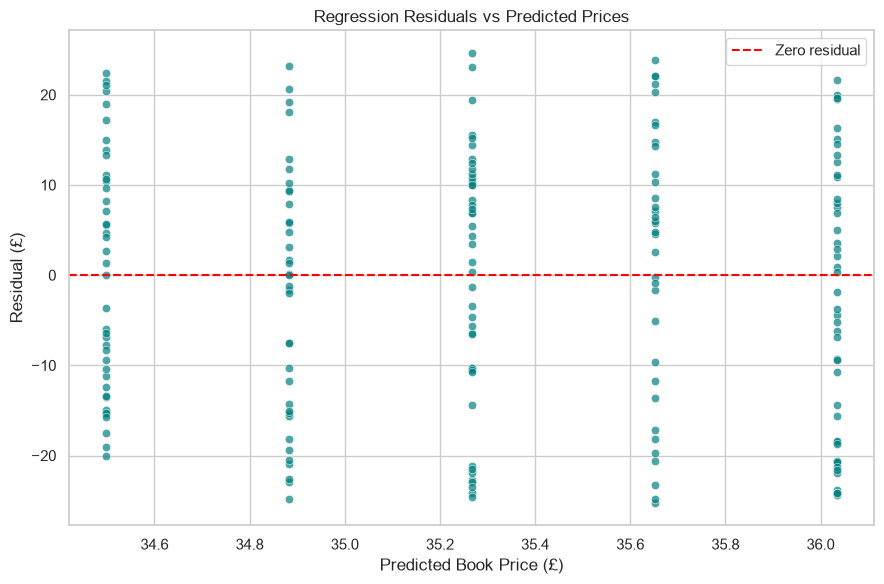

In [23]:
predictions = model.predict(X_test)
residuals = y_test - predictions

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=predictions,
    y=residuals,
    alpha=0.7,
    color="teal"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero residual"
)

plt.title("Regression Residuals vs Predicted Prices")
plt.xlabel("Predicted Book Price (£)")
plt.ylabel("Residual (£)")
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("LINEAR REGRESSION MODEL RESULTS")
print("-" * 40)
print(f"Mean Absolute Error (MAE): £{mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): £{rmse:.2f}")
print(f"R-squared (R²): {r2:.4f}")

LINEAR REGRESSION MODEL RESULTS
----------------------------------------
Mean Absolute Error (MAE): £12.23
Mean Squared Error (MSE): 200.9259
Root Mean Squared Error (RMSE): £14.17
R-squared (R²): -0.0053


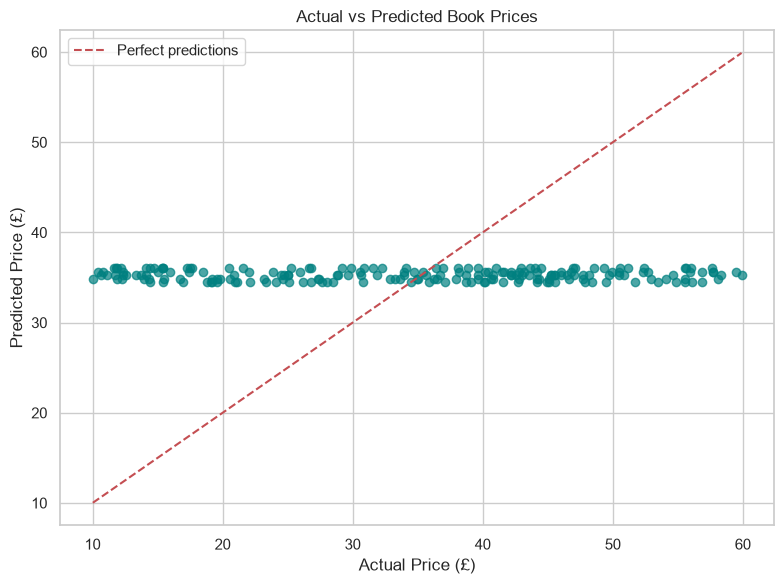

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.7,
    color="teal"
)

min_price = min(y_test.min(), predictions.min())
max_price = max(y_test.max(), predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect predictions"
)

plt.title("Actual vs Predicted Book Prices")
plt.xlabel("Actual Price (£)")
plt.ylabel("Predicted Price (£)")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
df_clean.to_csv("books_dataset_cleaned.csv", index=False)

results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R-squared"],
    "Value": [mae, mse, rmse, r2]
})

results.to_csv("model_evaluation_results.csv", index=False)
print("Cleaned dataset saved.")
print("Model evaluation results saved.")
display(results)

Cleaned dataset saved.
Model evaluation results saved.


,Metric,Value
0,MAE,12.231929
1,MSE,200.925866
2,RMSE,14.174832
3,R-squared,-0.005296


In [27]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X = df_clean[["rating", "genre"]]
y = df_clean["price_gbp"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("rating", SimpleImputer(strategy="median"), ["rating"]),
        ("genre", OneHotEncoder(handle_unknown="ignore"), ["genre"])
    ]
)

improved_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

improved_model.fit(X_train, y_train)

improved_predictions = improved_model.predict(X_test)
improved_mae = mean_absolute_error(y_test, improved_predictions)
improved_mse = mean_squared_error(y_test, improved_predictions)
improved_rmse = np.sqrt(improved_mse)
improved_r2 = r2_score(y_test, improved_predictions)

print("IMPROVED MODEL RESULTS")
print("-" * 35)
print(f"MAE: £{improved_mae:.2f}")
print(f"MSE: {improved_mse:.2f}")
print(f"RMSE: £{improved_rmse:.2f}")
print(f"R-squared: {improved_r2:.4f}")

IMPROVED MODEL RESULTS
-----------------------------------
MAE: £12.25
MSE: 204.71
RMSE: £14.31
R-squared: -0.0242


In [28]:
comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R-squared"],
    "Model 1: Rating only": [
        mae, mse, rmse, r2
    ],
    "Model 2: Rating and genre": [
        improved_mae,
        improved_mse,
        improved_rmse,
        improved_r2
    ]
})

display(comparison)

comparison.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully!")

,Metric,Model 1: Rating only,Model 2: Rating and genre
0,MAE,12.231929,12.250338
1,MSE,200.925866,204.712762
2,RMSE,14.174832,14.307787
3,R-squared,-0.005296,-0.024243


Model comparison saved successfully!


The book prices were predicted using two Linear Regression models. The first model employed star rating as the predictor and the second model added genre to star rating.

The first model's performance was determined by a Mean Absolute Error (MAE) of £12.23, a Root Mean Squared Error (RMSE) of £14.17, and an R-squared of -0.0053. The second model achieved an MAE of £12.25, an RMSE of £14.31, and an R-squared value of -0.0242.

The second model was not showing any improvement when predicting. The negative R-squared values for both models suggest that they did not perform as well on the test data as a simple baseline model that predicts using the mean price of the test data. The results indicate that the book price is not correctly predicted by these models based on these star ratings and genres.

Other book characteristics and other modelling techniques could be explored in future. Before making decisions any improvement to the model should be tested on held-out data.